# Práctica 3: Aprendizaje de modelos basados en redes neuronales

## Minería de Datos

### Curso académico 2024-2025

#### Profesorado:

* Juan Carlos Alfaro Jiménez
* José Antonio Gámez Martín

#### Alumnado:

* David López Lorenzo
* Carlos Martínez Jaén

En esta práctica, trabajaremos con modelos basados en redes neuronales utilizando, para ello, la librería `tensorflow`. Esta se trata de una de las más populares hoy en día debido a su facilidad de uso y versatilidad.

# 1. Preliminares

Importamos todas las librerias necesarias, confirmamos que estamos haciendo uso de la gpu de kaggle y creamos la semilla para la reproducibilidad.

In [2]:
import tensorflow as tf
from pathlib import Path
import tensorflow.keras as keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os
import shutil
from collections import defaultdict
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras import Sequential, layers, regularizers
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score
import warnings
!pip install plot_keras_history
from plot_keras_history import plot_history
import logging

# Para intentar que no salgan warnings en el Fine Tuning
warnings.filterwarnings('ignore')
logging.getLogger('tensorflow').setLevel(logging.ERROR)
warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

/opt/conda/lib/python3.10/pty.py:89: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid, fd = os.forkpty()


  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 324.5/324.5 kB 6.4 MB/s eta 0:00:00a 0:00:01
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
  Created wheel for plot_keras_history: filename=plot_keras_history-1.1.39-py3-none-any.whl size=10670 sha256=17e3a79bb90ad8af46859938b5ee170830ed6e8e9369a21b24f5ed098b8420f9
  Stored in directory: /root/.cache/pip/wheels/6d/89/e0/6781cca14c32fdba8e81404d9f09e1be1436deee5377160507
  Created wheel for sanitize_ml_labels: filename=sanitize_ml_labels-1.1.4-py3-none-any.whl size=324287 sha256=9e40229d4d0544f649ee49ad77a3c52bb6ab533009a6425e725cd62ecb015087
  Stored in directory: /root/.cache/pip/wheels/cc/37/0c/923ffeccf1ed550f523bb269e185103538592636861a48b84f
  Created wheel for compress-json: filename=compress_json-1.1.1-py3-none-any.whl size=6601 sha256=d2300bc6e73502ee97c7ca9fad53b1878b1b9552fbdf0486cbe9bda919e47154
  Stored in directory: /root/.cache/pip/wheels/41/5b/81/3d4b

In [3]:
# Get a list of physical devices visible to the host runtime
device_type = "GPU"  # The device type
devices = tf.config.list_physical_devices(device_type)

if not devices:
    # Raise an informative message when there are no devices in the host runtime
    raise RuntimeError(f"No {device_type} devices are used in the host.")

In [4]:
semilla = 12345

# 2. Carga de Datos

En lugar de cargar directamente los datos de la competición en nuestras variables de **train**, **validación** y **test**, seguimos estos pasos:

1. **Copiar los datos** al directorio **'kaggle/working/data'**. Esto nos permite trabajar con los datos de forma "local".
   
2. Usamos la función **split-folders** para dividir los datos en los tres conjuntos, **estratificando** correctamente las muestras en **train**, **validación** y **test**.

3. Al tener los datos en un directorio local, podemos fácilmente **identificar y eliminar** la imagen corrupta del conjunto de **test**.

In [5]:
!pip install split-folders
import splitfolders

In [6]:
competition = "los-simpson"  # The unique name of the competition
root = Path("..") / "input" / competition  # Directory with the subsets of the data

input = Path(root) / "train" # Directory to split
output = Path(".") / "data" # New directory

train_size = 0.8    # Fraction for train
validation_size = 0.2  # Fraction for validation

if not os.path.exists(output):
    # Divide in train and validation folders
    splitfolders.ratio(input, output=output, ratio=(train_size, validation_size), seed=semilla)
else:
    raise Warning(f"'{str(output)}' directory already exists.")

print("Imagenes de Test y Validación copiadas de forma estratificada")

Copying files: 16137 files [01:42, 158.12 files/s]

Imagenes de Test y Validación copiadas de forma estratificada


In [7]:
input_test = Path(root) / "test"  # Directorio de imágenes de prueba
output_test = Path(".") / "data" / "test"  # Directorio de destino para test

# Imagen corrupta
corrupt_image = input_test / "abraham_grampa_simpson/pic_0025.jpg"

# Crear el directorio de salida si no existe
os.makedirs(output_test, exist_ok=True)

# Copiar imágenes válidas
for class_dir in input_test.iterdir():
    if class_dir.is_dir():
        # Crear el subdirectorio en el destino
        output_class_dir = output_test / class_dir.name
        os.makedirs(output_class_dir, exist_ok=True)

        # Copiar cada archivo dentro de la clase
        for image_path in class_dir.iterdir():
            if image_path != corrupt_image and image_path.is_file():
                shutil.copy(image_path, output_class_dir)
print("Imagenes de Test copiadas al directorio local")

Imagenes de Test copiadas al directorio local


In [8]:
directory = Path(".") / "data" / "train"  # Directory where the data is located
batch_size = 32  # Size of the batches of data
image_size = (256, 256)  # Size to resize images to after they are read from disk

# Generate the training dataset from image files in the corresponding directory
train = keras.utils.image_dataset_from_directory(
    directory,
    batch_size = batch_size,
    image_size = image_size,
    seed = semilla)

Found 12899 files belonging to 25 classes.


In [9]:
directory = Path(".") / "data" / "val"  # Directory where the data is located

# Generate the validation dataset from image files in the corresponding directory
validation = keras.utils.image_dataset_from_directory(
    directory,
    batch_size = batch_size,
    image_size = image_size,
    seed = semilla)

Found 3238 files belonging to 25 classes.


In [10]:
directory = Path(".") / "data" / "test"  # Directory where the data is located

# Generate the validation dataset from image files in the corresponding directory
test = keras.utils.image_dataset_from_directory(
    directory,
    batch_size = batch_size,
    image_size = image_size,
    seed = semilla,
    shuffle = False)

Found 3936 files belonging to 25 classes.


# 3. Analísis breve de los datos

### 3.1. Visualización de la estratificación

Con lo que hemos hecho arriba, hemos divido los datos en train y validation de forma estratificada.

Con la tabla podemos confirmar que los 3 conjuntos están relativamente bien estratificados, por lo que hemos hecho bien el trabajo de momento.

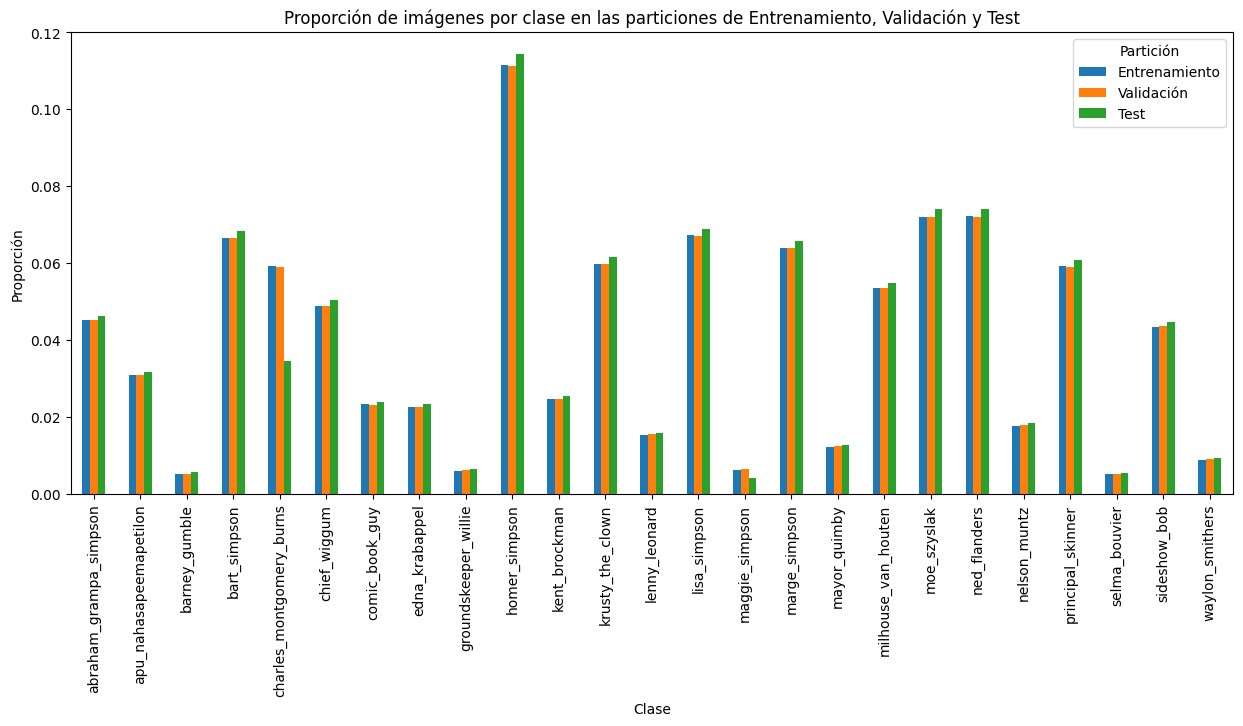

In [11]:
# Ignorar los warnings de pandas
warnings.simplefilter(action='ignore', category=FutureWarning)

# Función para extraer etiquetas de un dataset
def get_class_counts(dataset):
    labels = []
    for _, batch_labels in dataset:
        labels.extend(batch_labels.numpy())
    return pd.Series(labels).value_counts().sort_index()

# Obtener nombres de clases
class_names = train.class_names

# Calcular frecuencias para entrenamiento, validación y test
train_counts = get_class_counts(train)
val_counts = get_class_counts(validation)
test_counts = get_class_counts(test)

# Crear un DataFrame para comparar frecuencias absolutas
df_frequencies = pd.DataFrame({
    "Clase": class_names,
    "Entrenamiento": train_counts.values,
    "Validación": val_counts.values,
    "Test": test_counts.values
})

# Normalizar
df_proportions = df_frequencies.copy()
df_proportions.iloc[:, 1:] = df_proportions.iloc[:, 1:].astype('float64')
df_proportions.iloc[:, 1:] = df_proportions.iloc[:, 1:].div(df_proportions.iloc[:, 1:].sum(axis=0))

# Graficar proporciones
df_proportions.set_index("Clase").plot(kind="bar", figsize=(15, 6))
plt.title("Proporción de imágenes por clase en las particiones de Entrenamiento, Validación y Test")
plt.ylabel("Proporción")
plt.xlabel("Clase")
plt.xticks(rotation=90)
plt.legend(title="Partición")
plt.show()

### 3.2. Visualización aleatoria de los datos

Mostraremos unas cuantas imagenes del conjunto de entrenamiento de forma aleatoria para ver sus características.

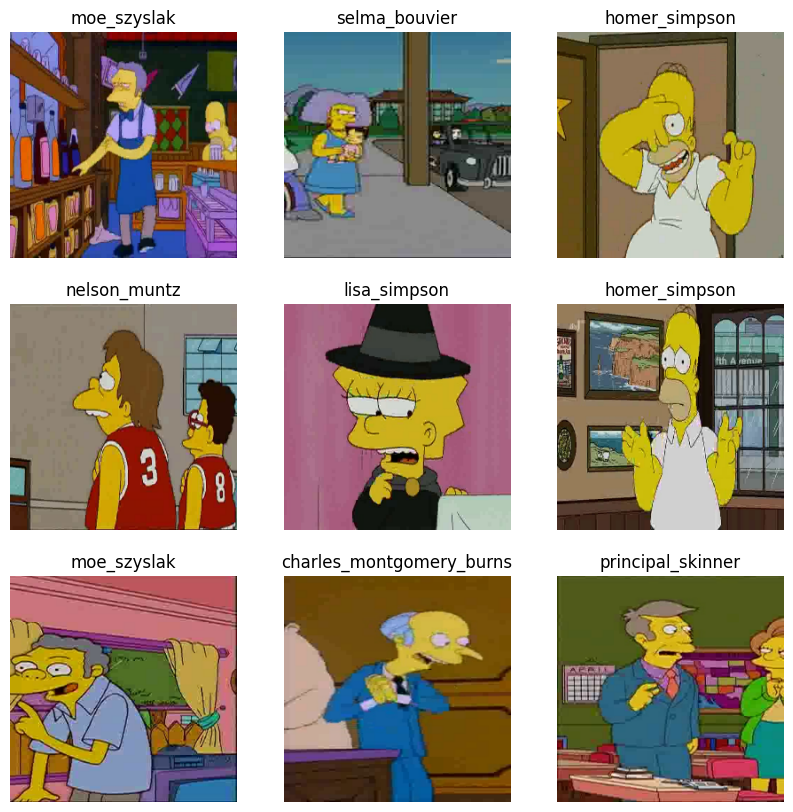

In [12]:
# Create a new figure
num = None  # A unique identifier for the figure
figsize = (10, 10)  # Width and height in inches
plt.figure(num, figsize)

# Create a dataset with one element
tensors = train.take(1)

# Get the class names from the training dataset
classes = train.class_names
classes = np.array(classes)

for images, labels in tensors:
    for i in range(9):
        # Transform the tensor to an array
        image = images[i]
        dtype = np.uint8  # Typecode to which the array is cast
        image = np.array(image).astype(dtype)

        # Get the class name of the image
        label = labels[i]
        label = classes[label]

        # Visualize the image
        rows = 3
        columns = 3
        index = i + 1
        option = "off"  # Hide all axis decorations
        ax = plt.subplot(rows, columns, index)
        plt.imshow(image)
        plt.title(label)
        plt.axis(option)

### 3.3. Distribución de las clases

La cantidad de imagenes de cada clase en el conjunto de entrenamiento puede estar descompensanda como vemos en la gráfica de abajo. Esto puede generar un sesgo a la hora de que nuestros modelos de redes neuronales aprendan, prestando más atención a las características de las clases predominantes (en este caso homer_simpson).

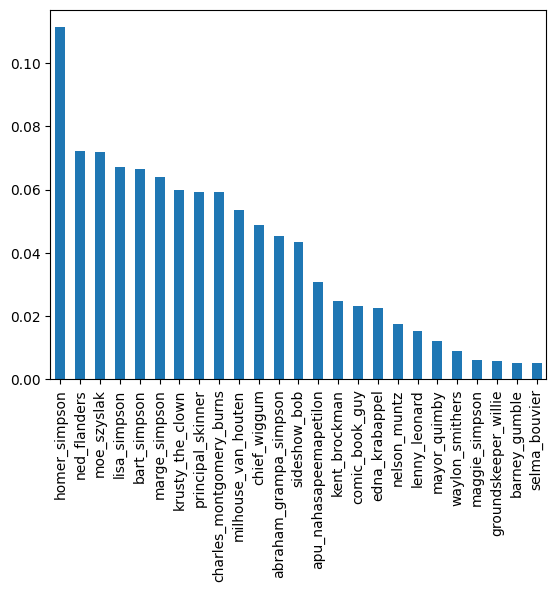

In [13]:
function = lambda file: file.split(os.sep)[2]
iterable = train.file_paths
generator = map(function, iterable)

data = list(generator)  # Data to be stored

normalize = True  # Return the relative frequencies of the unique values
sort = True  # Sort by frequencies
kind = "bar"  # The kind of plot to produce

pd.Series(data).value_counts(normalize, sort).plot(kind = kind);

# 4. Estudio de los recursos a utilizar
## 4.1. Ponderación de las clases

Para tratar de aliviar el problema que hemos comentado arriba, podemos usar la función compute_class_weight para asignarles pesos a cada una de las clases a la hora de entrenar, de esta forma balanceamos la falta de imagenes de algunas categorías y hacemos que nuestro modelo también aprenda las características de éstas.

Más abajo, pasamos el diccionario de pesos a formato Integer, ya que la función de entrenamiento no acepta los diccionarios de pesos con strings, si no con el número entero que representa la clase.

In [14]:
# Obtener las clases y sus frecuencias
class_frequencies = pd.Series(data).value_counts()

# Guardar la lista de clases para futuros usos
clases = list(class_frequencies.keys())

# Calcular los pesos de las clases
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=class_frequencies.index,
    y=data
)
class_weights_dict = dict(zip(class_frequencies.index, class_weights))

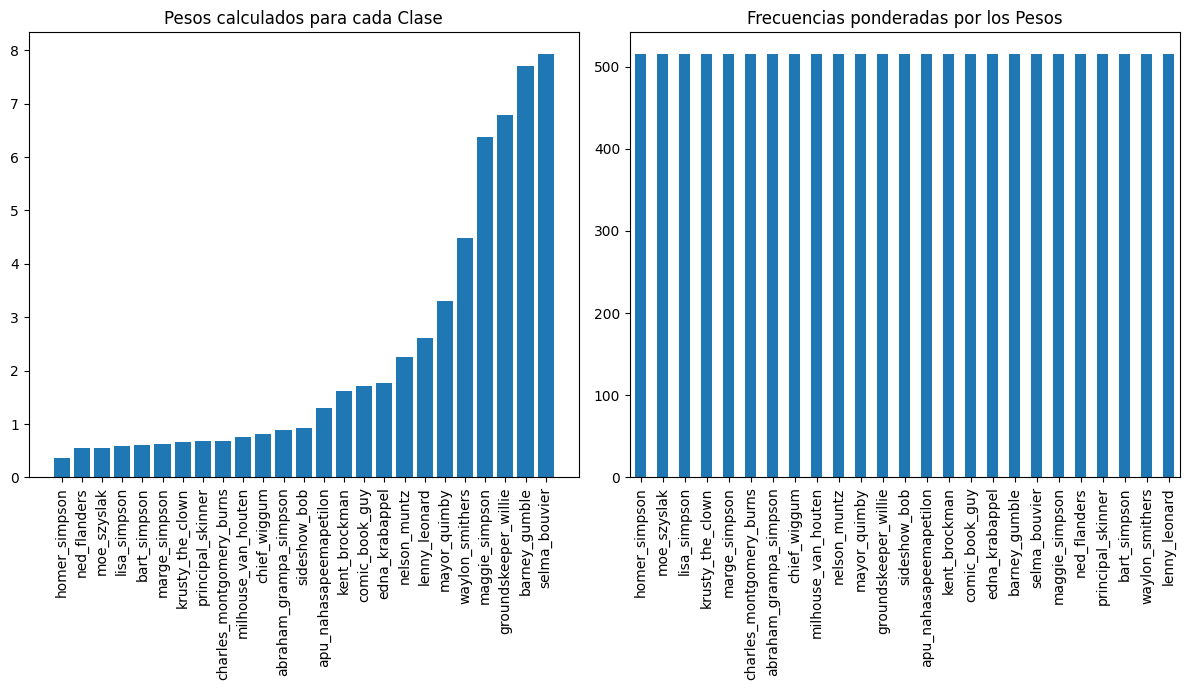

In [15]:
# Crear la figura con 2 columnas y 1 fila
fig, axes = plt.subplots(1, 2, figsize=(12, 7))  # (n_filas, n_columnas)

# Primer gráfico: Pesos de las clases
axes[0].bar(class_weights_dict.keys(), class_weights_dict.values())
axes[0].set_title('Pesos calculados para cada Clase')
# Usamos set_xticks para colocar las ubicaciones de las etiquetas
axes[0].set_xticks(range(len(class_weights_dict)))
axes[0].set_xticklabels(class_weights_dict.keys(), rotation=90)

# Segundo gráfico: Frecuencias ponderadas por clase
weighted_frequencies = class_frequencies * class_frequencies.index.map(class_weights_dict)
weighted_frequencies.sort_values(ascending=False).plot(kind='bar', ax=axes[1])
axes[1].set_title('Frecuencias ponderadas por los Pesos')

# Ajustar la disposición de los gráficos
plt.tight_layout()

# Mostrar los gráficos
plt.show()

In [16]:
# Codificar las etiquetas como enteros
encoder = LabelEncoder()
encoded_labels = encoder.fit_transform(clases)

# Convertir las keys de string a enteros
class_weights_int = {encoder.transform([k])[0]: v for k, v in class_weights_dict.items()}
class_weights_int

{9: 0.35930362116991643,
 19: 0.5547956989247311,
 18: 0.5559913793103448,
 13: 0.595796766743649,
 3: 0.6013519813519813,
 15: 0.6254060606060606,
 11: 0.6692088197146563,
 21: 0.6753403141361256,
 4: 0.6762254259501966,
 17: 0.747768115942029,
 5: 0.818984126984127,
 0: 0.8834931506849315,
 23: 0.9213571428571429,
 1: 1.2963819095477387,
 10: 1.6225157232704404,
 6: 1.7198666666666667,
 7: 1.766986301369863,
 20: 2.262982456140351,
 12: 2.6058585858585857,
 16: 3.3074358974358975,
 24: 4.486608695652174,
 14: 6.369876543209877,
 8: 6.788947368421053,
 2: 7.70089552238806,
 22: 7.937846153846154}

## 4.2. Aumentación de datos

Como nuestra base de datos es relativamente pequeña, ya que tenemos 25 clases diferentes que predecir, realizaremos un proceso simple de aumentación de datos en nuestra redes neuronales. Realizaremos un proceso de **Voltear, Girar, Hacer Zoom, Aumentar contraste o brillo** a nuestras imágenes de forma aleatoria, creando así nuevas **imágenes sintéticas** que pueden ayudar a nuestro modelo a entrenar mejor.

```python
# Voltea horizontal o verticalmente la imagen de forma aleatoria (unas sí, otras no)
layers.RandomFlip("horizontal")

# Gira un determinado ángulo la imagen original (0.1 -> 10% de giro máximo, 0.2 -> 20% de giro máximo)
layers.RandomRotation(0.2)

# Crea una imagen nueva haciendo zoom a la original (0.2 -> 20% de zoom)
layers.RandomZoom(0.2)

# Aumenta levemente el contraste de la imagen
layers.RandomContrast(0.2),

# Aumenta levemente el brillo de la imagen
layers.RandomBrightness(0.2), 

## 4.3 Capa de Dropout

La capa de **Dropout** es una técnica de regularización en redes neuronales que aleatoriamente "apaga" un porcentaje de neuronas durante el entrenamiento para **evitar el sobreajuste**, mejorando la generalización del modelo. Usaremos esta capa una vez al final del modelo, con la siguiente linea de código:


```python
layers.Dropout(0.5)

## 4.4. Callbacks

Los **callbacks** son herramientas para guardar el modelo durante el entrenamiento. En este caso, guardamos el mejor modelo encontrado, monitorizando la **pérdida de validación**.

- Guardamos cada modelo en un archivo diferente en el directorio **'kaggle/working'**, que es volátil, es decir, se borrará al finalizar la sesión. Por lo tanto, debemos descargar los archivos manualmente antes de que esto ocurra.

- También utilizamos una función de **Keras** con los callbacks (EarlyStopping), que no solo guarda el mejor modelo, sino que también monitorea el avance del entrenamiento. Si la **pérdida de validación** no mejora después de varias **epoch**, el entrenamiento se detiene de forma prematura, ya que se considera que el modelo ha convergido.

In [17]:
callbacksModeloSimple = [tf.keras.callbacks.ModelCheckpoint(filepath="/kaggle/working/checkpoint_file1.keras", save_best_only=True, monitor="val_loss")]
callbacksCNN = [tf.keras.callbacks.ModelCheckpoint(filepath="/kaggle/working/checkpoint_file2.keras", save_best_only=True, monitor="val_loss")]
callbacksTL = [tf.keras.callbacks.ModelCheckpoint(filepath="/kaggle/working/checkpoint_file3.keras", save_best_only=True, monitor="val_loss")]
callbacksFT = [tf.keras.callbacks.ModelCheckpoint(filepath="/kaggle/working/checkpoint_file4.keras", save_best_only=True, monitor="val_loss")]

In [18]:
paradaTemprana = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", # PARA DETERMINAR SI PARAMOS O NO, MONITOREAMOS LA PÉRDIDA DE VALIDACIÓN
    mode="auto", # COMO INDENTIFICAR MEJORAS (COMO ES UNA PERDIDA, MEJORAR ES REDUCIR)
    start_from_epoch=30, # A PARTIR DE QUÉ EPOCH EMPEZAMOS A MONITOREAR LA PÉRDIDA
    patience=5 # CUANTAS EPOCH SEGUIDAS TIENE QUE PASAR SIN MEJORAR PARA QUE SE PARE EL ENTRENAMIENTO
)

# Solo pondremos la parada temprana en los modelos que tardan mucho en entrenar, es decir, en los Transfer Learning
# Para el modelo convolucional y el modelo simple, ejecutaremos todas las epoch (100)
callbacksFT.append(paradaTemprana)
callbacksTL.append(paradaTemprana)

## 4.5. Estudio de modelos existentes para realizar Transfer Learning



En este proyecto, seleccionamos **Xception** y **DenseNet** como arquitecturas base para implementar **transfer learning** en la tarea de clasificación de imágenes. La decisión se basó en su estructura, capacidad para reutilizar conocimiento preentrenado y rendimiento en problemas similares.

### Xception: Precisión y eficiencia mediante convoluciones separables

**Xception** (Extreme Inception) es una evolución de la arquitectura Inception, diseñada para maximizar la eficiencia en el aprendizaje de características. Su innovación principal es el uso de **convoluciones separables en profundidad** (*depthwise separable convolutions*), que descomponen el proceso de convolución estándar en dos pasos:  
1. Una convolución *depthwise*, que aplica un único filtro por canal de entrada.  
2. Una convolución *pointwise*, que combina las salidas de los filtros *depthwise* con un filtro de 1x1.  

Esta separación reduce drásticamente el número de parámetros, permitiendo entrenar modelos más profundos sin un aumento significativo en el costo computacional.

#### Estructura y entrenamiento
- **Capas**: Xception tiene 36 bloques convolucionales agrupados en tres etapas: entrada, media y salida.  
- **Parámetros**: La arquitectura contiene aproximadamente **22.9 millones de parámetros**.  
- **Entrenamiento original**: Preentrenada en el conjunto de datos **ImageNet**, que contiene 1.2 millones de imágenes distribuidas en **1,000 clases**. Este entrenamiento proporciona una base robusta para *transfer learning* en problemas específicos.  

#### Aplicaciones y casos de uso
- Clasificación de imágenes en dominios diversos, como reconocimiento facial, análisis médico (e.g., diagnóstico de enfermedades en radiografías) y visión por computadora en vehículos autónomos.  
- Reconocida por su capacidad para generalizar en problemas con alta variabilidad visual.  

#### Relevancia en este proyecto
La capacidad de Xception para extraer características profundas y generalizables, junto con su eficiencia computacional, lo hace ideal para tareas complejas como la clasificación de imágenes en este trabajo.

### DenseNet: Reutilización de características y propagación eficiente

**DenseNet** (Densely Connected Convolutional Networks) introduce un enfoque innovador en el diseño de redes profundas al conectar cada capa directamente con todas las capas posteriores. En lugar de realizar una suma ponderada de características como en ResNet, DenseNet concatena las salidas de las capas previas, lo que:  
- Mejora la propagación del gradiente, reduciendo problemas de desvanecimiento.  
- Facilita la reutilización de características, permitiendo que las capas aprendan de una combinación de características de todos los niveles de la red.  
- Reduce el número de parámetros al compartir información entre capas.

#### Estructura y entrenamiento
- **Capas**: DenseNet se compone de bloques densos intercalados con capas de transición que reducen dimensionalidad mediante convoluciones y operaciones de agrupamiento (*pooling*).  
- **Parámetros**: En su configuración más utilizada (DenseNet121), tiene aproximadamente **8 millones de parámetros**, significativamente menos que Xception, lo que lo hace más ligero y eficiente.  
- **Entrenamiento original**: Preentrenada en **ImageNet**, con las mismas 1,000 clases y datos que Xception.  

#### Aplicaciones y casos de uso
- Análisis de imágenes médicas, como detección de tumores en mamografías y segmentación de órganos.  
- Clasificación en conjuntos de datos pequeños o medianos, donde su estructura ayuda a evitar el sobreajuste.  
- Reconocimiento de patrones en imágenes altamente texturizadas o con detalles finos.  

#### Relevancia en este proyecto
DenseNet es ideal para *transfer learning* en nuestro contexto porque su conectividad densa permite aprovechar al máximo las características preentrenadas en ImageNet, logrando un buen rendimiento incluso con conjuntos de datos más reducidos.

### Razones para descartar otras arquitecturas

1. **InceptionV3**: Aunque comparte principios con Xception, se descartó porque su rendimiento en términos de precisión es inferior, especialmente en tareas que requieren extraer características más abstractas y complejas.  
2. **EfficientNetB0**: Reconocida por su balance entre eficiencia y precisión, fue descartada ya que se había utilizado previamente en el ejemplo de referencia. El objetivo era explorar alternativas igualmente robustas, como Xception y DenseNet, que ofrecieran enfoques distintos.


# 5. Creación de modelos de redes neuronales

En los siguientes puntos crearemos la estructura de cada uno de los modelos elegidos para la práctica. En este caso hemos elegido 4 modelos de redes neuronales diferentes:
* **Red neuronal sencilla**: Una red sin convolución, completamente conectada.
* **Red neuronal convolucional**: Una red con convoluciónes, más sencilla y creada por nosotros.
* **Transfer Learning: Xception**: Importamos la estructura entrenada de una red convolucional mucho más compleja, y descongelamos todos sus parámetros entrenables.
* **Fine Tuning: Densenet201**: Importamos también la red, pero solo descongelamos algunas de sus capas finales y las modificamos muy poco a poco. Esta estructura se basa en convoluciones también pero están completamente conectadas entre sí (de ahí su nombre), por lo que puede captar características diferentes a Xception.

Después de esto realizaremos un **ensemble**, uniendo los 4 modelos y dándole pesos a cada uno según la confianza que tenemos en ellos, esto puede ayudar a combinar el poder predictivo y subir levemente el score y la robustez del modelo.

## 5.1. Modelo Simple

### Explicación Teórica

Estas redes utilizan únicamente **capas completamente conectadas**, sin capas convolucionales. Están diseñadas para procesar información como vectores de características, pero no están optimizadas para captar patrones espaciales en las imágenes, como lo haría una red convolucional.

### Descripción de la estructura del Modelo

1. **Capa de entrada**: Define la resolución de nuestras imágenes.
2. **Capas de aumento de datos**: Aplican transformaciones a las imágenes para mejorar la generalización.
3. **Capa de aplanamiento**: Convierte la imagen en un vector unidimensional.
4. **Tres bloques de capas completamente conectadas**: Cada bloque incluye **normalización** y **dropout** para mejorar la estabilidad y evitar el sobreajuste.
5. **Capa de salida**: Contiene 25 neuronas, cada una correspondiente a una de nuestras 25 clases a predecir.

Este modelo, al no utilizar capas convolucionales, asumimos que tendrá un rendimiento **bajo**, ya que no es capaz de captar patrones espaciales complejos, si no que solo maneja la información de cada píxel individualmente.

In [19]:
# Llama al modelo con este nombre que es el que utilizo luego en el ensemble porfa
modelMS = Sequential([
    layers.Input(shape=(256, 256, 3)),
    
    # Aumento de datos
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2), 
    layers.Rescaling(1./255),
    
    layers.Flatten("channels_last"),
    
    # Primera capa oculta
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    
    # Segunda capa oculta
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.6),
    
    # Tercera capa oculta
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.6),
    
    # Capa de salida
    layers.Dense(25, activation='softmax'),
])


lr = 0.0001  
modelMS.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=lr), 
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

modelMS.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 256, 256, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 196608)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    25,165,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 25)             │         3,225 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,237,145 (96.27 MB)

 Trainable params: 25,236,121 (96.27 MB)

 Non-trainable params: 1,024 (4.00 KB)

## 5.2. Modelo Complejo (CNN)

### Explicación Teórica
Las redes neuronales convolucionales (CNN) son modelos diseñados para **procesar imágenes**, aplicando **filtros** de diferentes tamaños para extraer características espaciales.

La principal diferencia de esta red con la anterior es el uso de capas de convolucón:
* La capa **Conv2D** toma una imagen y aplica **filtros** de diferente tamaños que **recorren la imagen**. Estos filtros ayudan a **detectar patrones** como bordes o texturas en la imagen.

* Las **convoluciones separables** dividen la operación de convolución en **dos pasos**: primero, se aplica un **filtro a cada canal** de la imagen por separado (como si se hiciera una convolución más simple), y luego se usan **filtros 1x1** para combinar los resultados. Esto reduce la cantidad de cálculos y hace que el modelo sea más rápido y eficiente, manteniendo un buen rendimiento.

### Descripción de la estructura del Modelo:
El modelo tendrá la estructura de capas siguiente:
* **Capa de entrada** de (256,256,3) como en todos nuestros modelos
* Una serie de **capas de aumento de datos**
* 4 bloques de **convolución** + normalización + maxpooling con regularización del kernel con l2. Los kernel son el tamaño de la matriz del filtro, en este caso 5x5. La regularización es un método que ayuda a evitar el sobreajuste aplicando penalizaciones (l2) a los pesos, reduce la complejidad del modelo y ayuda a generalizar.
* 1 bloque de **convolución separable** + normalización + maxpooling.
* **Capa GlobalAveragePooling2D**: parecido a una capa flatten pero en lugar de aplanar toda la matriz de características, calcula el valor promedio de cada mapa de características. Esto reduce el tamaño de la salida mientras mantiene la información global de la imagen.
* **Capa Dropout**: con una probabilidad del 50% de desactivar las neuronas. Esto, como ya hemos mencionado, ayuda a reducir el sobreajuste entrenando.
* La **capa de salida** con 25 neuronas y activación softmax
* **Learning Rate con Decaimiento** que explicamos abajo.

In [20]:
modelCNN = Sequential([
    # Capa de entrada
    layers.Input(shape=(256, 256, 3)),

    # Aumento de datos
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2),
    layers.RandomContrast(0.2),
    layers.RandomBrightness(0.2), 
    layers.Rescaling(1./255),

    # Primer bloque de convolución
    layers.Conv2D(filters=32, kernel_size=5, activation="relu", padding="same",kernel_regularizer=regularizers.l2(1e-4)),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=2),

    # Segundo bloque de convolución
    layers.Conv2D(filters=64, kernel_size=3, activation="relu", padding="same",kernel_regularizer=regularizers.l2(1e-4)),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=2),

    # Tercer bloque con convoluciones separables
    layers.SeparableConv2D(filters=128, kernel_size=3, activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=2),

    # Cuarto bloque de convolución
    layers.Conv2D(filters=256, kernel_size=3, activation="relu", padding="same",kernel_regularizer=regularizers.l2(1e-4)),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=2),

    # Quinto bloque de convolución
    layers.Conv2D(filters=512, kernel_size=3, activation="relu", padding="same",kernel_regularizer=regularizers.l2(1e-4)),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=2),

    # Global average pooling
    layers.GlobalAveragePooling2D(),

    # Evitar sobreajuste del modelo
    layers.Dropout(0.6),

    # Capa de salida
    layers.Dense(25, activation="softmax", kernel_regularizer=regularizers.l2(1e-4))
])


**Establecemos un learning rate con decaimiento**

De esta forma los cambios en los pesos serán mas bruscos al principio y más lentos en las últimas iteraciones, esto puede ayudar a los modelos a afinar los pesos en los últimos pasos. 

Lo usaremos en este modelo y en el Transfer Learning con Xception.

In [21]:
decaimiento = tf.keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=0.0001,
    decay_steps=4000, # Cada aproximadamente 10 epoch
    decay_rate=0.9, # se multiplica el learning rate por este valor
    staircase=True
)

In [22]:
# COMPILACIÓN Y VISUALIZACIÓN DEL MODELO 

optimizer = tf.keras.optimizers.Adam(decaimiento)
loss = "sparse_categorical_crossentropy" 
metrics = ["accuracy"] 

modelCNN.compile(optimizer, loss, metrics = metrics)

modelCNN.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)      │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 256, 256, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_1 (RandomZoom)      │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ (None, 256, 256, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_brightness               │ (None, 256, 256, 3)    │             0 │
│ (RandomBrightness)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 256, 256, 32)   │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 256, 256, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128, 128, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d                │ (None, 64, 64, 128)    │         8,896 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 64, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 32, 32, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 16, 16, 512)    │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 1,521,945 (5.81 MB)

 Trainable params: 1,519,961 (5.80 MB)

 Non-trainable params: 1,984 (7.75 KB)

## 5.3. Transfer Learning (Xception)

La explicación teórica de este modelo ya se ha explicado en la **sección 4.5**. 

### Descripción de la estructura del Modelo:
Para la creación de este modelo, además de importar Xception, añadiremos lo siguiente:
* **Descongelamos todas los parametros entrenables del modelo**: Esto hace que el entrenamiento sea mucho más costoso de cara al tiempo necesario para cada época, pero también aumenta bastante la adaptación de la estructura de la red a nuestro problema. Se sigue considerando Transfer Learning ya que los pesos iniciales del modelo se mantienen aun habiendo descongelado todos los parámetros, por lo que empezamos de un conocimiento existente y se mejora y retoca de ahí en adelante
* **Capa de entrada** de (256,256,3) como en todos nuestros modelos
* Una serie de **capas de aumento de datos**
* Dos **capas completamente conectadas** junto con una Dropout entre medias para evitar el sobreajuste
* La **capa de salida** con 25 neuronas y activación softmax
* **Learning Rate con Decaimiento**, como ya hemos mencionado antes

In [23]:
# CARGA DEL MODELO XCEPTION

include_top = False  # No incluir las capas superiores del modelo preentrenado
weights = "imagenet"  # Usar pesos preentrenados de ImageNet
shape = (256, 256, 3)  # Dimensiones de entrada (por ejemplo, (299, 299, 3))
data_format = "channels_last"  # Configuración de formato de datos (por defecto)
modelTL = tf.keras.applications.Xception(
    include_top=include_top,
    weights=weights,
    input_shape=shape
)

83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [24]:
# Descongelamos los parametros entrenables
modelTL.trainable = True

In [26]:
# Capa de entrada
inputs = keras.Input(shape=shape)

# Capas de aumento de datos
x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.2)(x)
x = layers.RandomZoom(0.2)(x)
x = layers.RandomContrast(0.2)(x)
x = layers.RandomBrightness(0.2)(x)
x = layers.Rescaling(1.0 / 255)(x)
x = modelTL(x)

# Capa de aplanamiento
x = layers.GlobalAveragePooling2D()(x)

# Capas completamente conectadas
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.6)(x)
x = layers.Dense(128, activation="relu")(x)

# Capa de salida
x = layers.Dense(25, activation="softmax")(x)

# Construcción del modelo final
modelTL = keras.Model(inputs, x)

In [27]:
# COMPILACIÓN Y VISUALIZACIÓN DEL MODELO

modelTL.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=decaimiento),
    loss='sparse_categorical_crossentropy',  # Para clasificación multiclase
    metrics=['accuracy']
)
modelTL.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_3 (RandomFlip)      │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_3               │ (None, 256, 256, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_3 (RandomZoom)      │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast_2               │ (None, 256, 256, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_brightness_2             │ (None, 256, 256, 3)    │             0 │
│ (RandomBrightness)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_3 (Rescaling)         │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ xception (Functional)           │ (None, 8, 8, 2048)     │    20,861,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 25)             │         3,225 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,143,489 (80.66 MB)

 Trainable params: 21,088,961 (80.45 MB)

 Non-trainable params: 54,528 (213.00 KB)

## 5.4. Fine Tuning (Densenet201)

La explicación teórica de este modelo ya se ha detallado en la **sección 4.5**.

### Descripción de la estructura del Modelo:
Para la creación de este modelo, además de importar **Densenet201**, añadimos las siguientes capas:
- Las capas de **entrada**, **aumentación de datos**, **densas**, **dropout** y **salida** siguen la misma estructura que el modelo anterior.
  
### Proceso de Fine Tuning:
Lo que diferencia este modelo de Fine Tuning es un proceso de entrenamiento en dos fases:

1. **Fase 1**: Descongelar solo las 10 últimas capas, utilizando un **learning rate medio-alto** y entrenar durante varias **epoch**.
2. **Fase 2**: Descongelar muchas más capas (las últimas 100) y entrenar usando un **learning rate mucho más bajo** para evitar modificar demasiado los pesos ya entrenados de la red.

A continuación, en las siguientes celdas de código, mostramos cómo preparar el modelo para el paso 1 y luego realizaremos el paso 2 durante el entrenamiento.

In [36]:
include_top = False
weights = "imagenet"  
input_shape = shape = (256, 256, 3) 

modelFT = tf.keras.applications.DenseNet201(
    include_top=include_top,
    weights=weights,
    input_shape=shape
)

# Congelamos todas al principio
modelFT.trainable = False

In [37]:
# Descongelar las últimas 10 capas
for layer in modelFT.layers[-10:]:
    layer.trainable = True


# Añadimos capas completamente conexas, dropout y de salida
x = modelFT.output
x = layers.GlobalAveragePooling2D()(x)

x = keras.layers.Dense(128, "relu")(x)
x = keras.layers.Dropout(0.6)(x)
x = keras.layers.Dense(128, "relu")(x)

# Capa de salida
x = keras.layers.Dense(25, "softmax")(x)

inputs = modelFT.input
outputs = x

modelFT = keras.Model(inputs, outputs)

In [38]:
# Ponemos un learning rate medio-alto para la primera pasada brusca de fine tuning
lr = 0.0001
optimizer = tf.keras.optimizers.Adam(lr)

modelFT.compile(optimizer, loss, metrics = metrics)
print("El modelo de densenet junto con las capas añadidas, hacen un total de "+str(len(modelFT.layers))+" capas.")

El modelo de densenet junto con las capas añadidas, hacen un total de 712 capas.


In [39]:
# Summary manual porque la tabla es enorme
trainable_params = sum([tf.reduce_prod(var.shape) for var in modelFT.trainable_variables])
non_trainable_params = sum([tf.reduce_prod(var.shape) for var in modelFT.non_trainable_variables])
total_params = trainable_params + non_trainable_params

print(f"Total params:         {total_params}")
print(f"Trainable params:     {trainable_params}")
print(f"Non-trainable params: {non_trainable_params}")

Total params:         18587611
Trainable params:     552025
Non-trainable params: 18035586


# 6. Entrenamiento y validación de modelos

* Para el modelo convolucional (CNN) como el Modelo Simple, realizaremos **100 epoch** ya que son mucho mas ligeras en cuestión de tiempo comparadas con los modelos Transfer Learning.

* Para el modelo de Xception y Fine Tuning realizaremos un entrenamiento con **100 epoch**, dejando a la función **EarlyStopping** si detener el modelo a partir de la epoch 30.

En todos los modelos **ponderaremos las clases con el diccionario de pesos** que hemos calculado en la sección 4.1. Esta parte del proceso puede llegar a tardar varias horas y necesitaremos activar el **acelerador gráfica GPU P100** de kaggle. En cada epoch de entrenamiento podemos ir viendo como aumenta el accuracy de validación y disminuye la pérdida de entrenamiento, esto nos puede dar una idea de cómo de bien está funcionando nuestro modelo y lo usaremos para asignar los pesos correspondientes posteriormente en el ensemble.

### Red Neuronal Sencilla

In [41]:
entrenamientoML = modelMS.fit(
    x = train,
    epochs = 100,
    validation_data = validation, 
    callbacks = callbacksModeloSimple,
    class_weight = class_weights_int)#Ponderar las clases para que entrene por igual'''

Epoch 1/100
404/404 ━━━━━━━━━━━━━━━━━━━━ 16s 29ms/step - accuracy: 0.0532 - loss: 4.2624 - val_accuracy: 0.1044 - val_loss: 3.3633
Epoch 2/100
404/404 ━━━━━━━━━━━━━━━━━━━━ 13s 31ms/step - accuracy: 0.0904 - loss: 3.7683 - val_accuracy: 0.1087 - val_loss: 3.2960
Epoch 3/100
404/404 ━━━━━━━━━━━━━━━━━━━━ 12s 30ms/step - accuracy: 0.1024 - loss: 3.5929 - val_accuracy: 0.1362 - val_loss: 3.2310
Epoch 4/100
404/404 ━━━━━━━━━━━━━━━━━━━━ 12s 30ms/step - accuracy: 0.1102 - loss: 3.5245 - val_accuracy: 0.1850 - val_loss: 2.8430
Epoch 5/100
404/404 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - accuracy: 0.1263 - loss: 3.3667 - val_accuracy: 0.2316 - val_loss: 2.7124
Epoch 6/100
404/404 ━━━━━━━━━━━━━━━━━━━━ 13s 31ms/step - accuracy: 0.1372 - loss: 3.2985 - val_accuracy: 0.2304 - val_loss: 2.6841
Epoch 7/100
404/404 ━━━━━━━━━━━━━━━━━━━━ 13s 31ms/step - accuracy: 0.1354 - loss: 3.1954 - val_accuracy: 0.2458 - val_loss: 2.6497
Epoch 8/100
404/404 ━━━━━━━━━━━━━━━━━━━━ 11s 26ms/step - accuracy: 0.1458 - loss: 3

### Red Neuronal Convolucional

In [42]:
entrenamientoCNN = modelCNN.fit(
    x = train,
    epochs = 100,
    validation_data = validation,
    callbacks = callbacksCNN,
    class_weight = class_weights_int)#Ponderar las clases para que entrene por igual

Epoch 1/100
404/404 ━━━━━━━━━━━━━━━━━━━━ 55s 122ms/step - accuracy: 0.0744 - loss: 4.0109 - val_accuracy: 0.1065 - val_loss: 3.4098
Epoch 2/100
404/404 ━━━━━━━━━━━━━━━━━━━━ 49s 120ms/step - accuracy: 0.1579 - loss: 3.1951 - val_accuracy: 0.2773 - val_loss: 2.6239
Epoch 3/100
404/404 ━━━━━━━━━━━━━━━━━━━━ 49s 120ms/step - accuracy: 0.1946 - loss: 2.9679 - val_accuracy: 0.3323 - val_loss: 2.4436
Epoch 4/100
404/404 ━━━━━━━━━━━━━━━━━━━━ 49s 120ms/step - accuracy: 0.2410 - loss: 2.7319 - val_accuracy: 0.3805 - val_loss: 2.3083
Epoch 5/100
404/404 ━━━━━━━━━━━━━━━━━━━━ 49s 120ms/step - accuracy: 0.2888 - loss: 2.5710 - val_accuracy: 0.4602 - val_loss: 2.0784
Epoch 6/100
404/404 ━━━━━━━━━━━━━━━━━━━━ 49s 120ms/step - accuracy: 0.3432 - loss: 2.3198 - val_accuracy: 0.4697 - val_loss: 2.0098
Epoch 7/100
404/404 ━━━━━━━━━━━━━━━━━━━━ 49s 120ms/step - accuracy: 0.3838 - loss: 2.1843 - val_accuracy: 0.5296 - val_loss: 1.8554
Epoch 8/100
404/404 ━━━━━━━━━━━━━━━━━━━━ 49s 120ms/step - accuracy: 0.4474 -

### Red con Transfer Learning

In [43]:
entrenamientoTL = modelTL.fit(
    x=train,
    epochs=100, # a partir de la 30, el early stop decide si parar
    validation_data=validation,
    callbacks=callbacksTL,
    class_weight=class_weights_int) #Ponderar las clases para que entrene por igual

Epoch 1/100
404/404 ━━━━━━━━━━━━━━━━━━━━ 244s 538ms/step - accuracy: 0.0702 - loss: 3.2028 - val_accuracy: 0.7820 - val_loss: 1.0063
Epoch 2/100
404/404 ━━━━━━━━━━━━━━━━━━━━ 215s 533ms/step - accuracy: 0.6747 - loss: 1.3541 - val_accuracy: 0.9179 - val_loss: 0.3231
Epoch 3/100
404/404 ━━━━━━━━━━━━━━━━━━━━ 215s 533ms/step - accuracy: 0.8629 - loss: 0.5555 - val_accuracy: 0.9413 - val_loss: 0.2281
Epoch 4/100
404/404 ━━━━━━━━━━━━━━━━━━━━ 215s 533ms/step - accuracy: 0.9047 - loss: 0.4104 - val_accuracy: 0.9527 - val_loss: 0.1837
Epoch 5/100
404/404 ━━━━━━━━━━━━━━━━━━━━ 215s 532ms/step - accuracy: 0.9247 - loss: 0.3151 - val_accuracy: 0.9629 - val_loss: 0.1569
Epoch 6/100
404/404 ━━━━━━━━━━━━━━━━━━━━ 214s 529ms/step - accuracy: 0.9420 - loss: 0.2446 - val_accuracy: 0.9503 - val_loss: 0.2009
Epoch 7/100
404/404 ━━━━━━━━━━━━━━━━━━━━ 215s 532ms/step - accuracy: 0.9435 - loss: 0.2351 - val_accuracy: 0.9651 - val_loss: 0.1463
Epoch 8/100
404/404 ━━━━━━━━━━━━━━━━━━━━ 214s 529ms/step - accuracy: 

### Red con Fine Tuning

Como ya hemos mencionado, en este proceso realizamos lo siguiente:

1. **Entrenamiento inicial**: Realizamos un entrenamiento con las capas congeladas y un **learning rate** inicial.
2. **Ajuste de capas y learning rate**: Después, modificamos las capas congeladas y ajustamos el **learning rate**.
3. **Recompilación del modelo**: Recompilamos el modelo con los nuevos ajustes.
4. **Entrenamiento final**: Finalmente, realizamos un entrenamiento más largo.

Este enfoque nos permite refinar el modelo y aprovechar el aprendizaje previo para mejorar el rendimiento.


In [40]:
print("Comienza el primer entrenamiento")
entrenamientoBruscoFT = modelFT.fit(
    x=train,
    epochs=20, # 20 iteraciones en el primer ajuste brusco
    validation_data=validation,
    callbacks=callbacksFT,
    class_weight=class_weights_int)

#----------------------------------------------------------------------------

# Descongelamos las últimas 500 capas del modelo base (aproximadamente el 70% de nuestro modelo)
for layer in modelFT.layers[-500:]:
    layer.trainable = True

# También descongelamos las 2 primeras capas para que se adapte mejor a nuestro problema
for layer in modelFT.layers[:2]:
    layer.trainable = True

# Compilamos nuevamente el modelo con un learning rate mucho más bajo
modelFT.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),  # Learning rate mas bajo que antes
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

#----------------------------------------------------------------------------
# Mostramos la cantidad de parametros entrenables para la segunda fase del entrenamiento
print("\nDespués del ajuste:")
trainable_params = sum([tf.reduce_prod(var.shape) for var in modelFT.trainable_variables])
non_trainable_params = sum([tf.reduce_prod(var.shape) for var in modelFT.non_trainable_variables])
total_params = trainable_params + non_trainable_params

print(f"Total params:         {total_params}")
print(f"Trainable params:     {trainable_params}")
print(f"Non-trainable params: {non_trainable_params}")

#-----------------------------------------------------------------------------
print("\nComienza el segundo entrenamiento")
# Entrenamos nuevamente el modelo 
entrenamientoFT = modelFT.fit(
    x=train,
    epochs=100, # a partir de la 30, el early stop decide si parar
    validation_data=validation,
    callbacks=callbacksFT,
    class_weight=class_weights_int)

Comienza el primer entrenamiento
Epoch 1/20
404/404 ━━━━━━━━━━━━━━━━━━━━ 110s 191ms/step - accuracy: 0.0512 - loss: 3.3737 - val_accuracy: 0.1350 - val_loss: 3.0634
Epoch 2/20
404/404 ━━━━━━━━━━━━━━━━━━━━ 48s 118ms/step - accuracy: 0.0939 - loss: 3.1762 - val_accuracy: 0.2196 - val_loss: 2.8951
Epoch 3/20
404/404 ━━━━━━━━━━━━━━━━━━━━ 48s 118ms/step - accuracy: 0.1489 - loss: 2.9852 - val_accuracy: 0.2872 - val_loss: 2.6265
Epoch 4/20
404/404 ━━━━━━━━━━━━━━━━━━━━ 48s 118ms/step - accuracy: 0.2084 - loss: 2.7383 - val_accuracy: 0.3450 - val_loss: 2.4051
Epoch 5/20
404/404 ━━━━━━━━━━━━━━━━━━━━ 48s 118ms/step - accuracy: 0.2627 - loss: 2.4183 - val_accuracy: 0.4447 - val_loss: 2.1048
Epoch 6/20
404/404 ━━━━━━━━━━━━━━━━━━━━ 49s 121ms/step - accuracy: 0.3110 - loss: 2.1792 - val_accuracy: 0.4910 - val_loss: 1.8906
Epoch 7/20
404/404 ━━━━━━━━━━━━━━━━━━━━ 49s 121ms/step - accuracy: 0.3828 - loss: 1.8864 - val_accuracy: 0.5488 - val_loss: 1.6656
Epoch 8/20
404/404 ━━━━━━━━━━━━━━━━━━━━ 49s 121ms

I0000 00:00:1734287294.910637     123 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'input_reduce_fusion_1651', 8 bytes spill stores, 8 bytes spill loads
ptxas warning : Registers are spilled to local memory in function 'input_reduce_select_fusion_91', 8 bytes spill stores, 8 bytes spill loads
ptxas warning : Registers are spilled to local memory in function 'input_reduce_select_fusion_90', 8 bytes spill stores, 8 bytes spill loads
ptxas warning : Registers are spilled to local memory in function 'input_reduce_select_fusion_89', 8 bytes spill stores, 8 bytes spill loads
ptxas warning : Registers are spilled to local memory in function 'input_reduce_fusion_1617', 8 bytes spill stores, 8 bytes spill loads
ptxas warning : Registers are spilled to local memory in function 'input_reduce_select_fusion_86', 4 bytes spill stores, 4 bytes spill loads
ptxas warning : Registers are spilled to local memory in function 'input_reduce_select_fusion_85', 8 byte

404/404 ━━━━━━━━━━━━━━━━━━━━ 421s 594ms/step - accuracy: 0.2987 - loss: 3.1244 - val_accuracy: 0.5318 - val_loss: 1.6071
Epoch 2/100
404/404 ━━━━━━━━━━━━━━━━━━━━ 97s 240ms/step - accuracy: 0.5547 - loss: 1.3179 - val_accuracy: 0.7072 - val_loss: 1.0493
Epoch 3/100
404/404 ━━━━━━━━━━━━━━━━━━━━ 96s 239ms/step - accuracy: 0.6572 - loss: 0.8987 - val_accuracy: 0.7613 - val_loss: 0.8575
Epoch 4/100
404/404 ━━━━━━━━━━━━━━━━━━━━ 100s 246ms/step - accuracy: 0.7327 - loss: 0.6861 - val_accuracy: 0.8045 - val_loss: 0.7321
Epoch 5/100
404/404 ━━━━━━━━━━━━━━━━━━━━ 100s 246ms/step - accuracy: 0.7782 - loss: 0.5509 - val_accuracy: 0.8311 - val_loss: 0.6403
Epoch 6/100
404/404 ━━━━━━━━━━━━━━━━━━━━ 100s 247ms/step - accuracy: 0.8301 - loss: 0.4199 - val_accuracy: 0.8484 - val_loss: 0.5772
Epoch 7/100
404/404 ━━━━━━━━━━━━━━━━━━━━ 99s 246ms/step - accuracy: 0.8581 - loss: 0.3555 - val_accuracy: 0.8613 - val_loss: 0.5287
Epoch 8/100
404/404 ━━━━━━━━━━━━━━━━━━━━ 100s 247ms/step - accuracy: 0.8838 - loss: 

### Ensemble de redes neuronales

Ya que hemos creado **4 modelos diferentes** para el mismo problema, vamos a realizar un ensemble de los mismos para aumentar la potencia discriminativa y la robustez de la predicción. El ensemble en sí no necesita entrenar, solo necesita las predicciones de los otros modelos entrenados. 

En este caso como hemos visto que el modelo de Transfer Learning y CNN es mejor que el Fine Tuning  y el Modelo Simple, vamos a aplicar al ensemble una ponderación para cada modelo. El modelo de Transfer Learning tendrá la mayor importancia en la decisión **(40%)**, seguido del modelo de CNN **(30%)**, el Fine Tuning **(20%)** y, por último el modelo simple **(10%)**.

In [58]:
# Predicciones de cada modelo
prediccionesModeloSimple = modelMS.predict(test)
prediccionesTL = modelTL.predict(test)
prediccionesCNN = modelCNN.predict(test)
prediccionesFT = modelFT.predict(test) 

# Ponderación de cada modelo
peso_TL = 0.4
peso_CNN= 0.3
peso_FT = 0.2
peso_MS = 0.0


# Predicción del ensemble
predicciones_ensemble = (peso_TL * prediccionesTL) + (peso_CNN * prediccionesCNN) + (peso_MS * prediccionesModeloSimple) + (peso_FT * prediccionesFT)

# Obtener las clases predichas (índice de la probabilidad máxima)
clases_predichas = np.argmax(predicciones_ensemble, axis=1)

123/123 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step
123/123 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step
123/123 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step
123/123 ━━━━━━━━━━━━━━━━━━━━ 9s 75ms/step


# 7. Evaluación y comparación de modelos

En este apartado, tras haber entrenado completamente todos los modelos y, habiendo guardado el mejor de cada uno en su correspondiente fichero checkpoint. Cargamos cada uno de ellos y obtenemos el rendimiento (score) frente al test. 

Esto solo se puede realizar una vez y es la métrica que realmente define cómo de bien funciona nuestro modelo contra datos que no ha visto en ningún momento.

In [44]:
# EVALUACIÓN DE LA RED NEURONAL SIMPLE

test_model_ML = tf.keras.models.load_model("/kaggle/working/checkpoint_file1.keras")
test_loss, test_acc_ms = test_model_ML.evaluate(test)
print(f"Test accuracy red simple: {test_acc_ms:.5f}")

123/123 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - accuracy: 0.3972 - loss: 2.1088
Test accuracy red simple: 0.40473


In [45]:
# EVALUACIÓN DE LA RED NEURONAL CONVOLUCIONAL

test_model_CNN = tf.keras.models.load_model("/kaggle/working/checkpoint_file2.keras")
test_loss, test_acc_mc = test_model_CNN.evaluate(test)
print(f"Test accuracy CNN: {test_acc_mc:.5f}")

123/123 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - accuracy: 0.9353 - loss: 0.3393
Test accuracy CNN: 0.94258


In [46]:
# EVALUACIÓN DE LA RED NEURONAL CON TRANSFER LEARNING

test_model_TL = tf.keras.models.load_model("/kaggle/working/checkpoint_file3.keras")
test_loss, test_acc_tl = test_model_TL.evaluate(test)
print(f"Test accuracy transfer learning: {test_acc_tl:.5f}")

123/123 ━━━━━━━━━━━━━━━━━━━━ 16s 114ms/step - accuracy: 0.9817 - loss: 0.1455
Test accuracy transfer learning: 0.98222


In [47]:
# EVALUACIÓN DE LA RED NEURONAL CON FINE TUNNING

test_model_FT = tf.keras.models.load_model("/kaggle/working/checkpoint_file4.keras")
test_loss, test_acc_ft = test_model_FT.evaluate(test)
print(f"Test accuracy fine tunning: {test_acc_ft:.5f}")

123/123 ━━━━━━━━━━━━━━━━━━━━ 25s 89ms/step - accuracy: 0.9383 - loss: 0.2897
Test accuracy fine tunning: 0.93979


## 7.1. Obtención del la lista de clases verdaderas (y_true)

Esta celda de codigo se utilizara para obtener lista de las clases verdaderas (y_true) del test. Necesitamos obtener esto para poder comparar el y_pred con el y_true y sacar el rendimiento del ensemble.

In [50]:
def obtener_clases_dataset_test(ruta_dataset_test):
    lista_clases = []
    transformacion_predichas = []
    
    for clase in sorted(os.listdir(ruta_dataset_test)):
        
        carpeta_clase = os.path.join(ruta_dataset_test, clase)
        if os.path.isdir(carpeta_clase):
            for imagen in os.listdir(carpeta_clase):
                if os.path.isfile(os.path.join(carpeta_clase, imagen)):
                    lista_clases.append(clase)

    for numero_clase in clases_predichas:
        transformacion_predichas.append(classes[numero_clase])
                    
    return lista_clases, transformacion_predichas


ruta_test = "/kaggle/working/data/test"
etiquetas_verdaderas, transformacion_predichas = obtener_clases_dataset_test(ruta_test)

In [59]:
# EVALUACIÓN DEL ENSEMBLE
exactitud_ensemble = accuracy_score(etiquetas_verdaderas, transformacion_predichas)
print(f"Test accuracy ensemble: {exactitud_ensemble:.5f}")

Test accuracy ensemble: 0.98323


## 7.2. Representación Gráfica de los resultados (test)

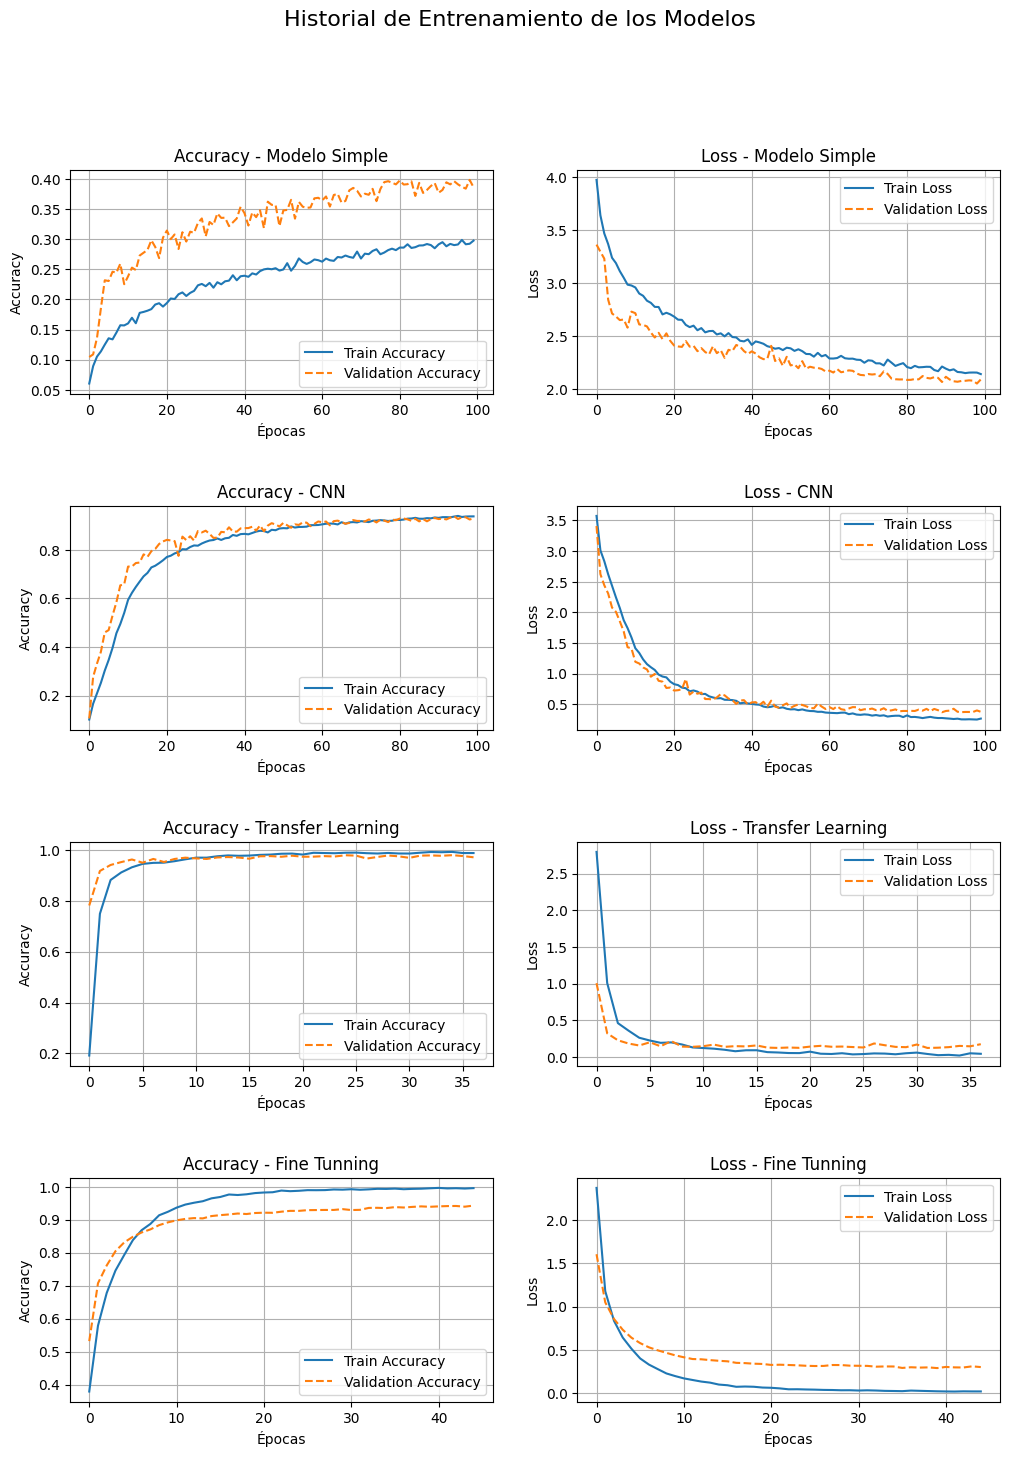

In [60]:
models_histories = {
    "Modelo Simple": entrenamientoML,
    "CNN": entrenamientoCNN,
    "Transfer Learning": entrenamientoTL,
    "Fine Tunning": entrenamientoFT
}

# Crear una figura con subplots organizados
fig, axes = plt.subplots(len(models_histories), 2, figsize=(12, 16))
fig.suptitle("Historial de Entrenamiento de los Modelos", fontsize=16)
fig.subplots_adjust(hspace=0.5)

# Iterar sobre los historiales de los modelos y ejes
for i, (model_name, history) in enumerate(models_histories.items()):
    # Graficar accuracy (si existe)
    if 'accuracy' in history.history:
        axes[i, 0].plot(history.history['accuracy'], label="Train Accuracy")
        if 'val_accuracy' in history.history:
            axes[i, 0].plot(history.history['val_accuracy'], linestyle="--", label="Validation Accuracy")
        axes[i, 0].set_title(f"Accuracy - {model_name}")
        axes[i, 0].set_xlabel("Épocas")
        axes[i, 0].set_ylabel("Accuracy")
        axes[i, 0].legend()
        axes[i, 0].grid(True)

    # Graficar loss
    axes[i, 1].plot(history.history['loss'], label="Train Loss")
    if 'val_loss' in history.history:
        axes[i, 1].plot(history.history['val_loss'], linestyle="--", label="Validation Loss")
    axes[i, 1].set_title(f"Loss - {model_name}")
    axes[i, 1].set_xlabel("Épocas")
    axes[i, 1].set_ylabel("Loss")
    axes[i, 1].legend()
    axes[i, 1].grid(True)

**Conclusiones de los gráficos de entrenamiento**

1. **Modelo Simple**: Consigue muy mal score de validación, aun teniendo 100 epoch en total de entrenamiento. Esto como ya hemos explicado es normal. Es curioso ver que obtiene mucho más en validación que en train, esto puede ser por que las imágenes de train sean mas complejas de predecir que las de validación.


2. **Modelo CNN**: Este es una de las que mejor han ido, podemos ver que la curva de validación apenas se despega de la curva de train. Tal vez con mas epoch hubiese dado mejor resultado.


3. **Modelo Xception**: Este modelo también sufre algo de sobreajuste, pero es el que mejor score de validación consigue, cosa normal ya que hemos descongelado todas las capas para el entrenamiento. Ha parado prematuramente (37/100) por la función de EarlyStopping, asi que nos hemos ahorrado mucho tiempo de entrenamiento innecesario.


4. **Modelo DenseNet** (FineTuning): En la gráfica del modelo podemos ver algo de sobreajuste, 99% en train y 94% en validación. También podemos ver como, aun habiéndole puesto 100 epoch, ha parado tempranamente en la 45, por lo que nuestra callback junto con la función EarlyStopping funciona correctamente.

<Figure size 640x480 with 0 Axes>

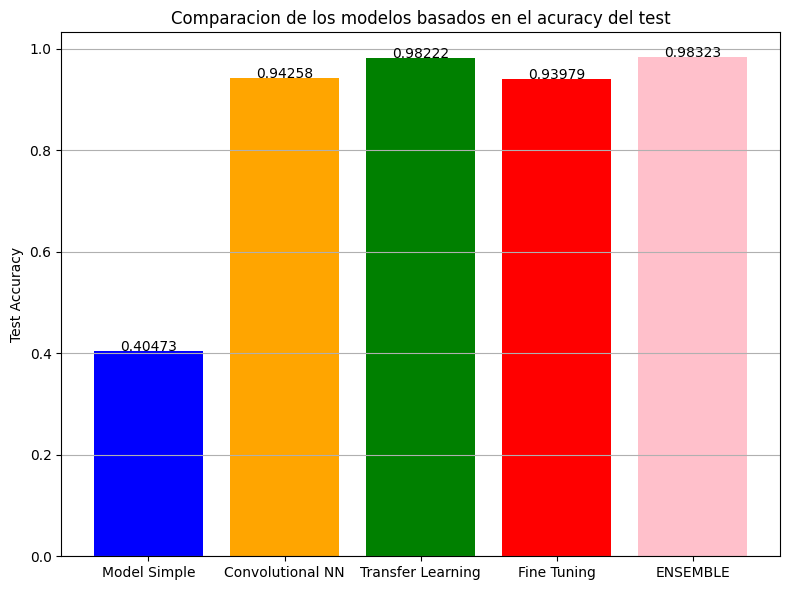

In [53]:
# Ajustar el diseño y mostrar la gráfica
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


# Graficar comparación de accuracies
models = ['Model Simple', 'Convolutional NN', 'Transfer Learning', 'Fine Tuning', 'ENSEMBLE']
accuracies = [test_acc_ms,test_acc_mc, test_acc_tl, test_acc_ft, exactitud_ensemble]

fig, ax = plt.subplots(figsize=(8, 6))
ax.bar(models, accuracies, color=['blue', 'orange', 'green', 'red', 'pink'])
ax.set_title('Comparacion de los modelos basados en el acuracy del test')
ax.set_ylabel('Test Accuracy')
ax.grid(axis='y')


for i, acc in enumerate(accuracies):
    ax.text(i, acc , f'{acc:.5f}', ha='center')

plt.tight_layout()
plt.show()

# 8. Conclusiones

1. **Eficiencia de las Redes Neuronales Convolucionales**  
   Las redes neuronales convolucionales (CNN) han demostrado ser significativamente más efectivas y eficientes para abordar problemas de clasificación de imágenes en comparación con redes densas tradicionales sin capas convolucionales. Su capacidad para capturar características espaciales y patrones visuales las convierte en una herramienta poderosa para este tipo de tareas.

2. **Desafíos en la optimización de modelos**  
   Diseñar una red neuronal que se ajuste perfectamente a un problema específico es un desafío considerable. La optimización de hiperparámetros y arquitectura sigue siendo un proceso artesanal que requiere muchas iteraciones de prueba y error.

3. **Problemas de sobreajuste**  
   Algunos de los modelos entrenados presentaron algo de sobreajuste a los datos de entrenamiento, como se puede observar en las tablas de progresión del entrenamiento. Esto ocurrió a pesar de haber implementado estrategias para mitigarlo, como el uso de capas de *Dropout* y *GlobalAveragePooling2D*.

4. **Ventajas del Ensemble**  
   Esta ha sido la primera vez que hemos programado un ensemble y vemos que combinar los votos de diferentes modelos mejora ligeramente el poder discriminativo y la robustez de las predicciones individuales, como era de esperar.

5. **Impacto del Transfer Learning y Fine Tuning**  
   Los procesos de *Transfer Learning* y *Fine Tuning* han demostrado ser herramientas extremadamente poderosas cuando se utilizan correctamente. Sin embargo, también representan un costo significativo en términos de tiempo de entrenamiento, ya que requieren un ajuste cuidadoso y recursos computacionales adecuados para maximizar su potencial.

6. **Limitaciones por restricciones de horas**  
   Durante el desarrollo, las horas limitadas de GPU proporcionadas por Kaggle presentaron un obstáculo considerable en el proceso de optimización. Esto impidió realizar todas las pruebas y ajustes necesarios para refinar nuestros modelos de manera más exhaustiva.

7. **Tiempo total de ejecución**  
   El tiempo total de ejecución de esta libreta ha sido de 5 horas y 45 minutos.
